# Advección periódica: barrido del número de componentes PCA

**Pregunta experimental.** ¿Cómo cambia el desempeño de la PINN con PCA al variar el número de componentes espaciales y cómo se compara con una PINN estándar?

Este experimento extiende el piloto de advección. Compara la selección automática de componentes que retiene al menos 99% de la varianza con valores fijos `k = 2, 4, 6, 8`, usando la PINN base como referencia. La evaluación es empírica y se limita al problema y al presupuesto descritos abajo.

## Protocolo

- Diez semillas (2041–2050), con la misma partición temporal, minibatches, puntos de colocación PDE, tiempos de frontera periódica y puntos de condición inicial para todos los modelos de cada semilla.
- 2000 pasos de optimización y la misma arquitectura de coeficientes/neuronas que el experimento piloto; cantidades de parámetros comparables entre modelos.
- La base PCA se ajusta solamente con snapshots temporales de entrenamiento. El modelo predice los coeficientes temporales y reconstruye el campo con los primeros `k` modos.
- La pérdida de advección `u_t + c u_x` se calcula mediante autodiferenciación de JAX en todos los modelos. El residuo de prueba se evalúa con una métrica común de diferencias sobre la grilla.
- El tiempo de pipeline incluye el ajuste de PCA cuando aplica; la compilación se registra aparte.

Este diseño emparejado reduce diferencias debidas al muestreo aleatorio. El barrido sirve para identificar candidatos, no para afirmar que exista un `k` universalmente óptimo.

In [ ]:
from pathlib import Path
import json
from IPython.display import display, HTML, SVG

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RUN_DIR = ROOT / "results/advection/base_vs_pca/k_sweep_10_seeds_v1"
RESULT = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))


def html_table(headers, rows):
    head = "".join(f"<th>{h}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    return f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"


def stat(name, metric, digits=4):
    value = RESULT["summary"][name][metric]
    return f"{value['mean']:.{digits}g} ± {value['std']:.{digits}g}"


## Resultados agregados en prueba

Se reporta media ± desviación estándar entre semillas. En `k` fijo se informa la varianza acumulada promedio que esos componentes retuvieron.

In [1]:
ORDER = ["PINN base", "PCA AD 99%", "PCA AD k=2", "PCA AD k=4", "PCA AD k=6", "PCA AD k=8"]
rows = []
for name in ORDER:
    item = RESULT["summary"][name]
    k = "—" if item["k"] is None else f"{item['k']['mean']:.0f}"
    retained = "—" if item["retained_variance"] is None else f"{100*item['retained_variance']['mean']:.4f}% ± {100*item['retained_variance']['std']:.3g}%"
    rows.append([name, k, retained, stat(name, "test_relative_l2"), stat(name, "test_pde_residual_rms"), stat(name, "test_periodic_boundary_rms", 3), stat(name, "pipeline_seconds", 3)])
display(HTML(html_table(["Modelo", "k", "Varianza retenida", "Error relativo L2 (prueba)", "Residuo PDE RMS (prueba)", "Defecto periódico RMS", "Pipeline (s)"], rows)))


Modelo,k,Varianza retenida,Error relativo L2 (prueba),Residuo PDE RMS (prueba),Defecto periódico RMS,Pipeline (s)
PINN base,—,—,0.05397 ± 0.008044,0.01196 ± 0.002372,0.0388 ± 0.00824,3.07 ± 0.0657
PCA AD 99%,3,99.6606% ± 0.0264%,0.1125 ± 0.01805,0.4933 ± 0.07137,5.66e-08 ± 1.23e-08,2.61 ± 0.0329
PCA AD k=2,2,96.1519% ± 0.293%,0.3653 ± 0.02291,0.9101 ± 0.09538,3.59e-08 ± 2.57e-08,2.6 ± 0.0479
PCA AD k=4,4,100.0000% ± 2.51e-06%,0.002649 ± 0.0006843,0.01596 ± 0.004556,7.62e-08 ± 2.02e-08,2.63 ± 0.0705
PCA AD k=6,6,100.0000% ± 2.51e-06%,0.4188 ± 0.04719,0.3202 ± 0.04449,0.000239 ± 0.000151,2.68 ± 0.058
PCA AD k=8,8,100.0000% ± 2.51e-06%,0.776 ± 0.06003,0.4665 ± 0.06169,0.000349 ± 0.000215,2.61 ± 0.0933


## Error de solución y residuo físico

La figura resume el compromiso entre error relativo de la solución y residuo PDE. Las barras muestran la dispersión entre semillas. El residuo de prueba se calcula con el mismo procedimiento para todas las variantes.

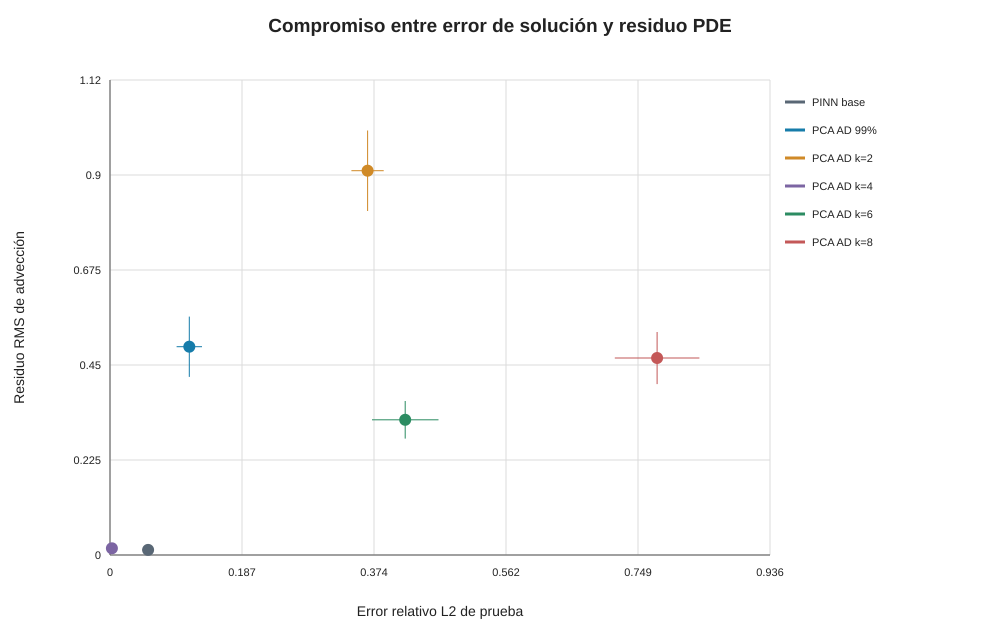

In [1]:
display(SVG(filename=str(RUN_DIR / "error_residual_tradeoff.svg")))

## Comparación completa y curvas de entrenamiento

La siguiente figura compara las métricas de prueba con la PINN base. Las curvas de validación muestran su evolución durante el presupuesto de 2000 pasos; la gráfica de tiempo permite comprobar que PCA redujo el tiempo total del pipeline en esta configuración.

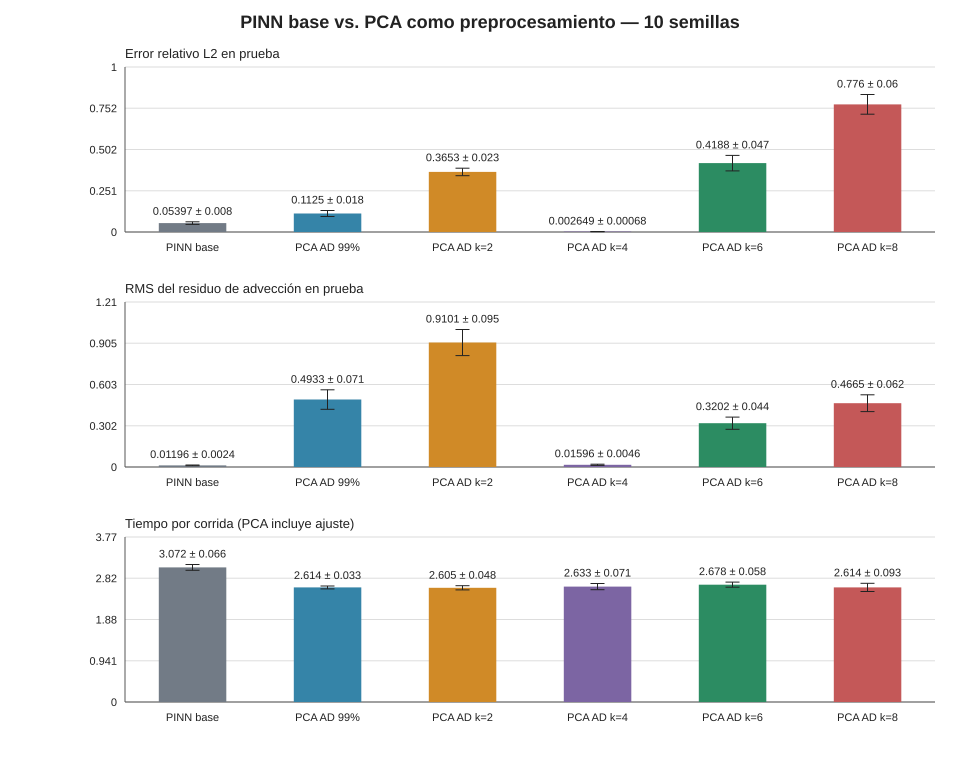

In [1]:
display(SVG(filename=str(RUN_DIR / "comparison.svg")))

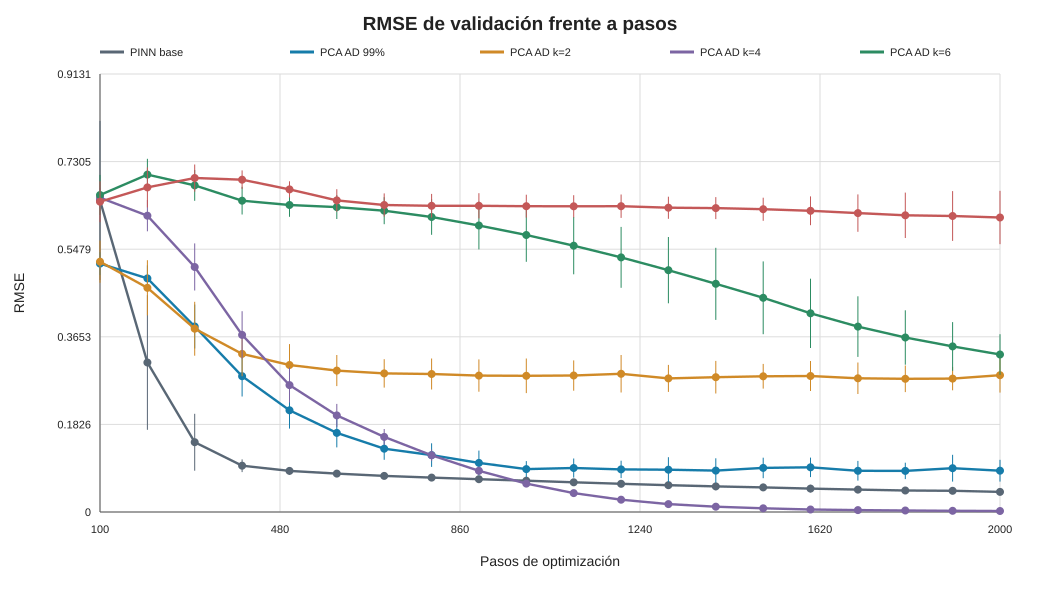

In [1]:
display(SVG(filename=str(RUN_DIR / "validation_rmse_vs_steps.svg")))

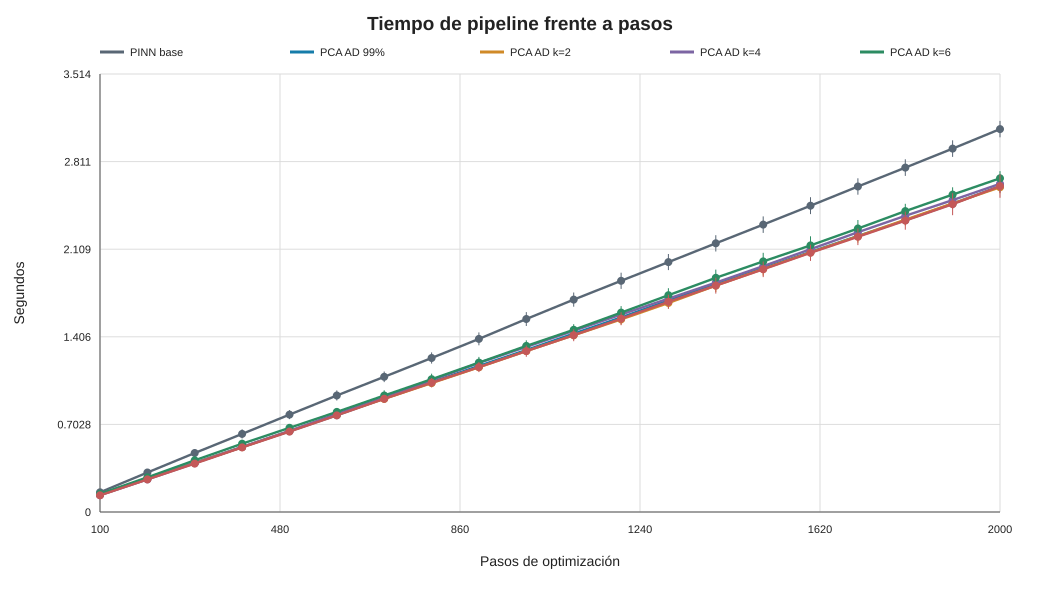

In [1]:
display(SVG(filename=str(RUN_DIR / "pipeline_time_vs_steps.svg")))

## Comparación pareada contra la PINN base

`Δ` es PCA menos PINN base dentro de cada semilla; valores negativos favorecen PCA en esa métrica. El conteo indica cuántas de las diez semillas favorecieron a PCA.

In [1]:
rows = []
for name in ORDER[1:]:
    m = RESULT["paired_differences_PCA_minus_base"][name]
    e, p, t = (m[key] for key in ("test_relative_l2", "test_pde_residual_rms", "pipeline_seconds"))
    rows.append([name, f"{e['PCA_minus_base_mean']:+.5f}", f"{e['PCA_better_count']}/10", f"{p['PCA_minus_base_mean']:+.5f}", f"{p['PCA_better_count']}/10", f"{t['PCA_minus_base_mean']:+.3f}", f"{t['PCA_better_count']}/10"])
display(HTML(html_table(["Modelo", "Δ error L2 medio", "Semillas con menor error", "Δ residuo PDE medio", "Semillas con menor residuo", "Δ tiempo pipeline (s)", "Semillas más rápidas"], rows)))


Modelo,Δ error L2 medio,Semillas con menor error,Δ residuo PDE medio,Semillas con menor residuo,Δ tiempo pipeline (s),Semillas más rápidas
PCA AD 99%,+0.05854,0/10,+0.48129,0/10,-0.458,10/10
PCA AD k=2,+0.31134,0/10,+0.89812,0/10,-0.467,10/10
PCA AD k=4,-0.05132,10/10,+0.00400,2/10,-0.439,10/10
PCA AD k=6,+0.36479,0/10,+0.30822,0/10,-0.394,10/10
PCA AD k=8,+0.72204,0/10,+0.45455,0/10,-0.458,10/10


## Lectura del experimento

- La selección por 99% retuvo en promedio **99,66%** con `k=3`, pero no produjo la menor solución de prueba: su error relativo L2 medio fue **0,1125**, mayor que el de la PINN base (**0,0540**).
- `k=4` fue el mejor de este barrido para reconstruir `u`: error relativo L2 **0,00265 ± 0,00068** y menor error que la PINN base en **10/10 semillas**. Retuvo prácticamente toda la varianza de los snapshots y el residuo PDE medio (**0,01596**) quedó cerca del valor base (**0,01196**), aunque fue menor que el base solo en 2/10 semillas.
- El defecto periódico de `k=4` fue prácticamente cero, y su pipeline medio tomó **2,63 s** frente a **3,07 s** de la PINN base. Estos tiempos son de esta máquina/configuración y no deben interpretarse como una aceleración general.
- `k=6` y `k=8` rindieron peor que `k=4` pese a retener esencialmente 100% de la varianza. Esto muestra que retener más componentes no garantiza mejor resultado con un presupuesto de entrenamiento finito. El experimento no determina por sí solo por qué empeora la optimización.

En esta condición inicial la solución está generada a partir de dos frecuencias espaciales, `sin(πx)` y `0.5 cos(2πx)`. Al desplazarse en el tiempo, cada frecuencia puede requerir componentes seno y coseno, lo que es consistente con que cuatro modos describan bien el campo. Esta interpretación es específica de este caso de prueba; debe comprobarse con otras condiciones iniciales y problemas antes de generalizarla.

## Alcance y siguiente comprobación

El resultado favorece `k=4` como candidato para este benchmark, no como regla universal. El próximo chequeo razonable es repetir el barrido con otra condición inicial periódica y aumentar el presupuesto o validar el valor elegido en semillas/condiciones que no participaron en la selección. Así podremos separar la estructura particular del campo de una mejora reproducible del método.

## Reproducibilidad

La configuración está en `configs/advection_k_sweep.json`, el ejecutor en `scripts/run_advection_k_sweep.py` y las métricas/figuras en `results/advection/base_vs_pca/k_sweep_10_seeds_v1/`.

Para regenerar la corrida desde la raíz del repositorio:

```powershell
.venv-jax-latest\Scripts\python.exe scripts\run_advection_k_sweep.py --config configs\advection_k_sweep.json
```

Los resultados mostrados arriba son los outputs guardados de esa corrida. El notebook también puede volver a leerlos ejecutando sus celdas.